# 01. Линейная регрессия: базовые поля и добавленные признаки

Линейная модель складывает вклады входных признаков. Используем Ridge — линейную регрессию с ограничением величины коэффициентов, чтобы связанные признаки не делали решение нестабильным. Сначала обучаем её на исходных категориях, затем на полном наборе.

## Две версии одной модели

| Версия | Что видит модель |
|---|---|
| Базовые поля, 5 входов | Склад, артикул, два уровня категории и характеристика товара |
| С FE, 50 входов | Те же поля + календарь, история продаж, вчерашние остатки, общие продажи склада/товара и явные сочетания |

Внутри пары одинаковы обучающие строки, временные границы, функция потерь и правило выбора момента остановки. Меняется набор входов. FE — создание дополнительных признаков; все определения есть в [словаре](../features/FEATURES.md). Подготовка нулевых дней нужна обеим версиям и не считается различием между ними.

**Как читаем качество.** MAE — средняя абсолютная ошибка в штуках; меньше лучше. WAPE — суммарная абсолютная ошибка / суммарные продажи, в таблицах это доля. RMSE сильнее штрафует большие ошибки. RMSLE считает ошибку в логарифмической шкале. Смещение (bias) — средний прогноз минус факт; отрицательное значение означает недопрогноз. Валидация выбирает настройки, тест проверяет уже выбранную модель.

In [1]:
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'docs/datasets').is_dir())

import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from features.catalog import LABELS, GROUP_LABELS, MODEL_LABELS, feature_label, identifier_label, display_ru
plt.rcParams.update({'date.autoformatter.month':'%m.%Y','date.autoformatter.day':'%d.%m',
                     'date.autoformatter.year':'%Y'})

RAW = ROOT / 'docs/datasets'
PROCESSED = ROOT / 'data/processed'
PROCESSED.mkdir(parents=True, exist_ok=True)
SEED = 42
pd.set_option('display.max_columns', 80)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})


from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_squared_log_error
OUT=ROOT/'data/artifacts/training'; MODELS=ROOT/'data/models'
OUT.mkdir(parents=True,exist_ok=True); MODELS.mkdir(parents=True,exist_ok=True)
manifest=json.loads((PROCESSED/'feature_manifest.json').read_text())
frames={s:pd.read_parquet(PROCESSED/f'{s}.parquet') for s in ['train','valid','test']}
FEATURE_SETS=manifest['feature_sets']
ALL_CATS=FEATURE_SETS['fe']['categorical']
for df in frames.values():
    for c in ALL_CATS: df[c]=df[c].astype('string').fillna('__MISSING__').astype(str)
assert frames['train'].date.max()<frames['valid'].date.min()<frames['test'].date.min()
assert set(FEATURE_SETS['base']['categorical'])<=set(ALL_CATS)

def metrics(y,pred):
    y=np.asarray(y,dtype='float64'); pred=np.maximum(np.asarray(pred,dtype='float64'),0)
    assert np.isfinite(pred).all() and len(y)==len(pred)
    return {'MAE':float(mean_absolute_error(y,pred)),
            'WAPE':float(np.abs(y-pred).sum()/y.sum()) if y.sum()>0 else np.nan,
            'RMSE':float(np.sqrt(mean_squared_error(y,pred))),
            'RMSLE':float(np.sqrt(mean_squared_log_error(y,pred))),
            'bias':float(np.mean(pred-y))}

def save_result(name,predictions,seconds,family,setting,columns,params):
    records=[]; output=[]
    for split,pred in predictions.items():
        pred=np.maximum(np.asarray(pred),0)
        records.append({'model':name,'family':family,'feature_set':setting,'feature_count':len(columns),
                        'split':split,**metrics(frames[split].quantity,pred),'fit_seconds':float(seconds)})
        p=frames[split][['date','pair_id','quantity']].copy(); p['prediction']=pred; p['split']=split; output.append(p)
    result=pd.DataFrame(records)
    result.to_csv(OUT/f'{name}_metrics.csv',index=False)
    pd.concat(output,ignore_index=True).to_parquet(PROCESSED/f'{name}_predictions.parquet',index=False)
    contract={'model':name,'family':family,'feature_set':setting,'features':columns,'parameters':params,
              'seed':SEED,'train_rows':len(frames['train']),
              'train_end':manifest['train_end'],'valid_start':manifest['valid_start'],'test_start':manifest['test_start']}
    (OUT/f'{name}_experiment.json').write_text(json.dumps(contract,indent=2,ensure_ascii=False))
    display_ru(result.round(5))
    return result

def show_pair(family):
    rows=pd.concat([pd.read_csv(OUT/f'{family}_{s}_metrics.csv') for s in ['base','fe']])
    display_ru(rows[['model','feature_count','split','MAE','WAPE','RMSE','bias']].round(5))
    for split in ['valid','test']:
        p=rows[rows.split.eq(split)].set_index('feature_set')
        gain=100*(1-p.loc['fe','MAE']/p.loc['base','MAE'])
        display(Markdown(f"**{MODEL_LABELS[split]}:** MAE меняется с {p.loc['base','MAE']:.4f} до {p.loc['fe','MAE']:.4f}; улучшение {gain:+.1f}%. Плюс означает уменьшение ошибки."))
    return rows

def fit_plot(y,pred,title,filename):
    fig,axes=plt.subplots(1,2,figsize=(13,4))
    z=pd.DataFrame({'actual':np.asarray(y),'predicted':np.maximum(pred,0)})
    z['bin']=pd.cut(z.predicted,[-.001,.1,.25,.5,1,2,4,8,16,np.inf])
    calibration=z.groupby('bin',observed=True).agg(actual=('actual','mean'),predicted=('predicted','mean'))
    axes[0].plot(calibration.predicted,calibration.actual,'o-')
    mx=max(calibration.predicted.max(),calibration.actual.max()); axes[0].plot([0,mx],[0,mx],'--',alpha=.5)
    axes[0].set(xlabel='Средний прогноз',ylabel='Средний факт',title='Калибровка: совпадает ли прогноз с фактом')
    residual=z.predicted-z.actual
    axes[1].hist(residual.clip(residual.quantile(.01),residual.quantile(.99)),bins=60)
    axes[1].set(xlabel='Прогноз минус факт: центральные 98%',title=title)
    plt.tight_layout(); plt.savefig(OUT/filename,dpi=160,bbox_inches='tight'); plt.show()

display_ru(pd.DataFrame([{'split':s,'rows':len(f),'date_min':f.date.min().date(),'date_max':f.date.max().date()} for s,f in frames.items()]))
print('Протокол: прогноз на день по данным, известным по конец предыдущего дня.')

,Период,Число строк,Первая дата,Последняя дата
0,Обучение,600000,2024-01-29,2026-06-05
1,Валидация,245758,2026-06-06,2026-07-03
2,Тест,245784,2026-07-04,2026-07-31


Протокол: прогноз на день по данным, известным по конец предыдущего дня.


## Простые ориентиры до обучения

Проверяем три правила: всегда ноль, повторить продажи неделю назад, взять среднее прошлых семи дней. Это прогнозы без обучаемых коэффициентов; «парное обучение» к ним не применяется. Их история заканчивается вчера. При отсутствии истории используем среднее только по обучению.

In [2]:
fallback=float(frames['train'].quantity.mean())
for name,col in [('seasonal_lag7','qty_lag_7'),('rolling_mean7','qty_roll_mean_7')]:
    preds={s:frames[s][col].fillna(fallback).to_numpy() for s in ['valid','test']}
    save_result(name,preds,0,'reference','reference',[col],{'rule':name})
save_result('zero',{s:np.zeros(len(frames[s])) for s in ['valid','test']},0,'reference','reference',[],{'rule':'zero'})

,Модель,Семейство модели,Признак = set,Число признаков,Период,"MAE, шт.","WAPE, доля","RMSE, шт.",RMSLE,"Смещение, шт.","Время обучения, с"
0,Продажи 7 дней назад,Простое правило,Простое правило,1,Валидация,0.39904,1.04706,1.12823,0.40675,-0.00208,0.0
1,Продажи 7 дней назад,Простое правило,Простое правило,1,Тест,0.41422,1.03628,1.16845,0.41323,-0.00340,0.0


,Модель,Семейство модели,Признак = set,Число признаков,Период,"MAE, шт.","WAPE, доля","RMSE, шт.",RMSLE,"Смещение, шт.","Время обучения, с"
0,Среднее прошлых 7 дней,Простое правило,Простое правило,1,Валидация,0.34520,0.90578,0.86104,0.32106,-0.00120,0.0
1,Среднее прошлых 7 дней,Простое правило,Простое правило,1,Тест,0.35717,0.89355,0.88182,0.32539,0.00032,0.0


,Модель,Семейство модели,Признак = set,Число признаков,Период,"MAE, шт.","WAPE, доля","RMSE, шт.",RMSLE,"Смещение, шт.","Время обучения, с"
0,Всегда ноль,Простое правило,Простое правило,0,Валидация,0.38111,1.0,1.38110,0.46557,-0.38111,0.0
1,Всегда ноль,Простое правило,Простое правило,0,Тест,0.39972,1.0,1.43842,0.47728,-0.39972,0.0


,model,Семейство модели,Набор входов,feature_count,split,MAE,WAPE,RMSE,RMSLE,bias,fit_seconds
0,zero,Простое правило,Простое правило,0,valid,0.381107,1.0,1.381100,0.465571,-0.381107,0.0
1,zero,Простое правило,Простое правило,0,test,0.399721,1.0,1.438416,0.477275,-0.399721,0.0


## Одинаковая регрессия на двух наборах

One-hot кодирование превращает категорию в отдельный индикатор: например, «это склад 0». Числовые признаки заполняем медианами обучения и приводим к сопоставимому масштабу. Эти преобразования не учатся на валидации или тесте. Сила ограничения коэффициентов `alpha=100` одинакова в обеих версиях; перебор настроек здесь не нужен для сравнения FE.

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
import joblib
trained={}; coefficient_tables={}
params={'alpha':100.0,'solver':'lsqr','tol':1e-4,'max_iter':250}
for setting,spec in FEATURE_SETS.items():
    cats=spec['categorical']; nums=spec['numeric']; columns=cats+nums
    transformers=[('category',OneHotEncoder(handle_unknown='ignore',min_frequency=20,dtype=np.float32),cats)]
    if nums:
        numeric=Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),('scale',StandardScaler())])
        transformers.insert(0,('numeric',numeric,nums))
    preprocessor=ColumnTransformer(transformers,sparse_threshold=1.0)
    start=time.perf_counter()
    X_train=preprocessor.fit_transform(frames['train'][columns])
    X_valid=preprocessor.transform(frames['valid'][columns]); X_test=preprocessor.transform(frames['test'][columns])
    model=Ridge(**params).fit(X_train,frames['train'].quantity)
    elapsed=time.perf_counter()-start
    predictions={'valid':np.maximum(model.predict(X_valid),0),'test':np.maximum(model.predict(X_test),0)}
    name=f'linear_{setting}'
    save_result(name,predictions,elapsed,'linear',setting,columns,params)
    joblib.dump({'preprocessor':preprocessor,'model':model,'features':columns},MODELS/f'{name}.joblib')
    coefficients=pd.DataFrame({'feature':preprocessor.get_feature_names_out(),'coefficient':model.coef_})
    coefficients['abs_coefficient']=coefficients.coefficient.abs()
    coefficients.sort_values('abs_coefficient',ascending=False).to_csv(OUT/f'{name}_coefficients.csv',index=False)
    trained[setting]=(model,predictions); coefficient_tables[setting]=coefficients
show_pair('linear')

,Модель,Семейство модели,Признак = set,Число признаков,Период,"MAE, шт.","WAPE, доля","RMSE, шт.",RMSLE,"Смещение, шт.","Время обучения, с"
0,Ridge: базовые поля,Линейная регрессия (Ridge),Базовые поля,5,Валидация,0.40687,1.06760,1.13619,0.35470,-0.10547,1.61904
1,Ridge: базовые поля,Линейная регрессия (Ridge),Базовые поля,5,Тест,0.42414,1.06109,1.19716,0.36371,-0.12412,1.61904


,Модель,Семейство модели,Признак = set,Число признаков,Период,"MAE, шт.","WAPE, доля","RMSE, шт.",RMSLE,"Смещение, шт.","Время обучения, с"
0,Ridge: с FE,Линейная регрессия (Ridge),С добавленными признаками,50,Валидация,0.34988,0.91806,0.82598,0.30573,0.01155,9.15522
1,Ridge: с FE,Линейная регрессия (Ridge),С добавленными признаками,50,Тест,0.36349,0.90936,0.84109,0.31105,0.01800,9.15522


,Модель,Число признаков,Период,"MAE, шт.","WAPE, доля","RMSE, шт.","Смещение, шт."
0,Ridge: базовые поля,5,Валидация,0.40687,1.06760,1.13619,-0.10547
1,Ridge: базовые поля,5,Тест,0.42414,1.06109,1.19716,-0.12412
0,Ridge: с FE,50,Валидация,0.34988,0.91806,0.82598,0.01155
1,Ridge: с FE,50,Тест,0.36349,0.90936,0.84109,0.01800


**Валидация:** MAE меняется с 0.4069 до 0.3499; улучшение +14.0%. Плюс означает уменьшение ошибки.

**Тест:** MAE меняется с 0.4241 до 0.3635; улучшение +14.3%. Плюс означает уменьшение ошибки.

,model,Семейство модели,Набор входов,feature_count,split,MAE,WAPE,RMSE,RMSLE,bias,fit_seconds
0,linear_base,linear,base,5,valid,0.406871,1.067604,1.136188,0.354698,-0.105475,1.619041
1,linear_base,linear,base,5,test,0.424140,1.061091,1.197158,0.363714,-0.124118,1.619041
0,linear_fe,linear,fe,50,valid,0.349879,0.918060,0.825976,0.305725,0.011548,9.155222
1,linear_fe,linear,fe,50,test,0.363491,0.909362,0.841093,0.311054,0.018002,9.155222


## Как читаем коэффициенты

Слева — вклады исходных категорий в базовой модели, справа — числовые признаки полной модели. После стандартизации коэффициент числового признака соответствует сдвигу примерно на одно стандартное отклонение обучения. Положительный коэффициент увеличивает прогноз при фиксированных остальных входах. Это связь внутри модели, а не причинный эффект.

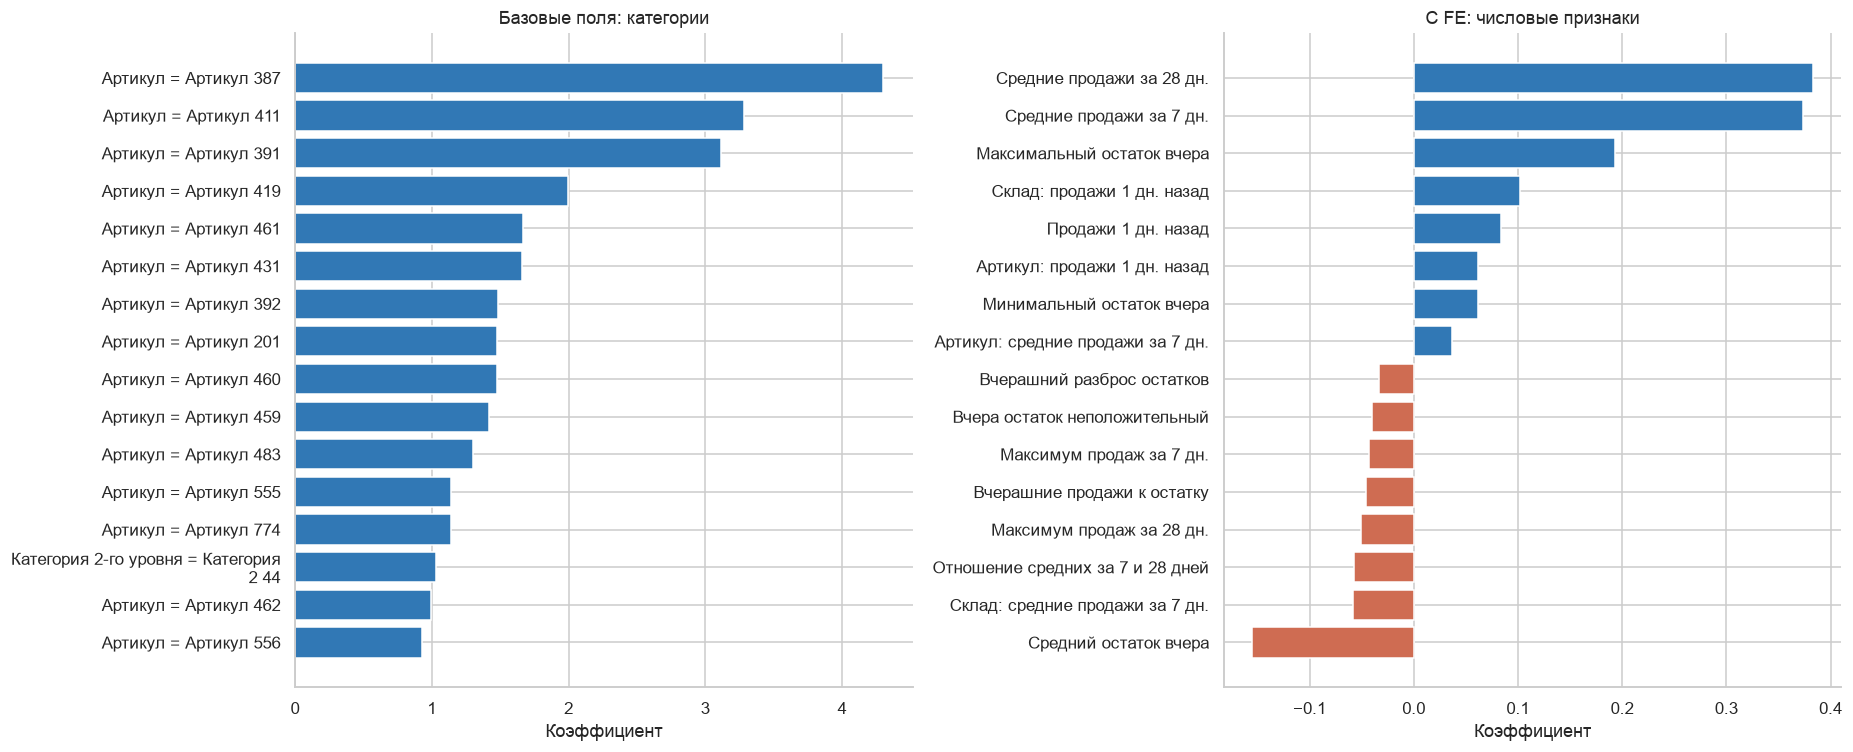

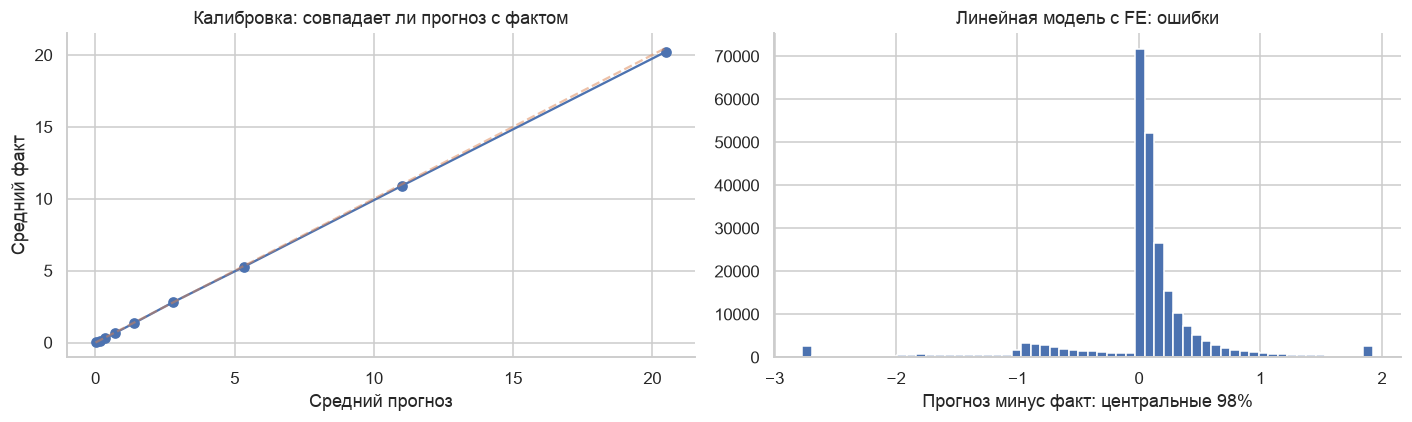

In [4]:
fig,axes=plt.subplots(1,2,figsize=(17,7))
for ax,setting,prefix,title in [(axes[0],'base','category__','Базовые поля: категории'),(axes[1],'fe','numeric__','С FE: числовые признаки')]:
    c=coefficient_tables[setting]
    top=c[c.feature.str.startswith(prefix)].nlargest(16,'abs_coefficient').sort_values('coefficient')
    ax.barh([feature_label(f,width=34) for f in top.feature],top.coefficient,color=np.where(top.coefficient.ge(0),'#3178b5','#cf6c52'))
    ax.set_title(title); ax.set_xlabel('Коэффициент')
plt.tight_layout(); plt.savefig(OUT/'01_linear_coefficients.png',dpi=160,bbox_inches='tight'); plt.show()
fit_plot(frames['test'].quantity,trained['fe'][1]['test'],'Линейная модель с FE: ошибки','02_linear_calibration.png')

## Что означает сравнение

Разница между двумя строками Ridge показывает пользу созданных признаков при одной линейной модели. Если полного набора недостаточно для качества, это ещё не доказывает отсутствие сигнала: связи могут быть нелинейными. Их проверяет следующий ноутбук с CatBoost.